# CIFAR-100 + SVD classroom demo (colour images)

1. Load a **few** CIFAR-100 images (32 × 32 colour pictures of everyday objects).
2. Show that a colour image is stored as a **32 × 32 × 3** array: one 32 × 32 matrix per Red, Green and Blue channel.
3. Discuss how to apply SVD, which only works on 2-D matrices, to a 3-D colour array.
4. **Method A — per-channel SVD:** decompose R, G and B separately, truncate each to rank $k$, stack them back.
5. **Method B — unfold to one matrix:** place the three channels side by side as a 32 × 96 matrix and do a single SVD.
6. Compare original vs. reconstructions for $k = 5, 10, 15, 20$ (images are 32 × 32, so rank ≤ 32).
7. Repeat for several images at once.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

np.set_printoptions(linewidth=220)

## 1. Load a few CIFAR-100 images

CIFAR-100 ships as one archive (~160 MB), so the file is downloaded once, but we keep only a handful of images in memory.
The loader tries Keras, then torchvision.

In [ ]:
N_IMAGES = 8          # how many images to keep

def load_cifar100_few(n):
    try:                                      # option A: tensorflow / keras
        from tensorflow.keras.datasets import cifar100
        (x, y), _ = cifar100.load_data(label_mode="fine")
        return x[:n], y[:n].ravel()
    except ImportError:
        pass
    # option B: torchvision
    from torchvision import datasets
    ds = datasets.CIFAR100(root="./data", train=True, download=True)
    return ds.data[:n], np.array(ds.targets[:n])

# the 100 fine-grained class names, in label order
CLASS_NAMES = ["apple","aquarium_fish","baby","bear","beaver","bed","bee","beetle","bicycle","bottle",
    "bowl","boy","bridge","bus","butterfly","camel","can","castle","caterpillar","cattle","chair",
    "chimpanzee","clock","cloud","cockroach","couch","crab","crocodile","cup","dinosaur","dolphin",
    "elephant","flatfish","forest","fox","girl","hamster","house","kangaroo","keyboard","lamp",
    "lawn_mower","leopard","lion","lizard","lobster","man","maple_tree","motorcycle","mountain","mouse",
    "mushroom","oak_tree","orange","orchid","otter","palm_tree","pear","pickup_truck","pine_tree","plain",
    "plate","poppy","porcupine","possum","rabbit","raccoon","ray","road","rocket","rose","sea","seal",
    "shark","shrew","skunk","skyscraper","snail","snake","spider","squirrel","streetcar","sunflower",
    "sweet_pepper","table","tank","telephone","television","tiger","tractor","train","trout","tulip",
    "turtle","wardrobe","whale","willow_tree","wolf","woman","worm"]

images, labels = load_cifar100_few(N_IMAGES)
print(f"Kept {images.shape[0]} images, each of shape {images.shape[1:]}  (height, width, channels)")
print(f"Pixel range: {images.min()} .. {images.max()}")
print("Labels:", [CLASS_NAMES[l] for l in labels])

Kept 8 images, each of shape (32, 32, 3)  (height, width, channels)
Pixel range: 0 .. 255
Labels: ['cattle', 'dinosaur', 'apple', 'boy', 'aquarium_fish', 'telephone', 'train', 'cup']


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/torchvision/datasets/cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


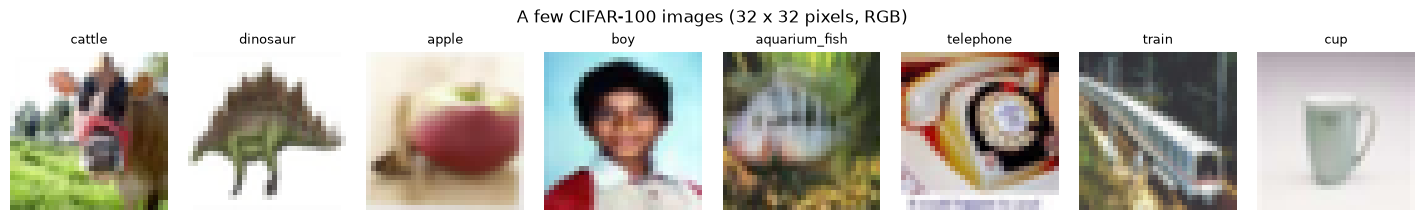

In [ ]:
fig, axes = plt.subplots(1, N_IMAGES, figsize=(1.8 * N_IMAGES, 2.2))
for ax, img, lab in zip(axes, images, labels):
    ax.imshow(img); ax.set_title(CLASS_NAMES[lab], fontsize=9); ax.axis("off")
plt.suptitle("A few CIFAR-100 images (32 x 32 pixels, RGB)")
plt.tight_layout(); plt.show()

## 2. A colour image is a 32 × 32 × 3 array

A grayscale image (like MNIST) is a single matrix. A colour image has **three** matrices stacked together,
one each for Red, Green and Blue. Every pixel is a triple $(r, g, b)$ with values from 0 to 255.

In [ ]:
idx = 0                                  # change to look at another of the loaded images
img = images[idx].astype(float)          # shape (32, 32, 3)
R, G, B = img[:, :, 0], img[:, :, 1], img[:, :, 2]

print(f"Image #{idx} ('{CLASS_NAMES[labels[idx]]}') has shape {img.shape}")
print(f"Each channel is a {R.shape} matrix.\n")
print("Pixel at row 10, column 10 is the RGB triple:", img[10, 10].astype(int))
print("\nTop-left 8 x 8 corner of the RED channel:")
print(R[:8, :8].astype(int))

Image #0 ('cattle') has shape (32, 32, 3)
Each channel is a (32, 32) matrix.

Pixel at row 10, column 10 is the RGB triple: [115 134 124]

Top-left 8 x 8 corner of the RED channel:
[[255 255 255 255 255 255 255 255]
 [255 254 254 254 254 254 254 254]
 [255 254 255 255 255 255 255 255]
 [255 254 255 255 255 255 255 253]
 [255 254 255 255 255 255 255 253]
 [255 254 255 255 255 255 255 252]
 [255 254 255 255 255 255 255 254]
 [255 254 255 255 255 255 255 253]]


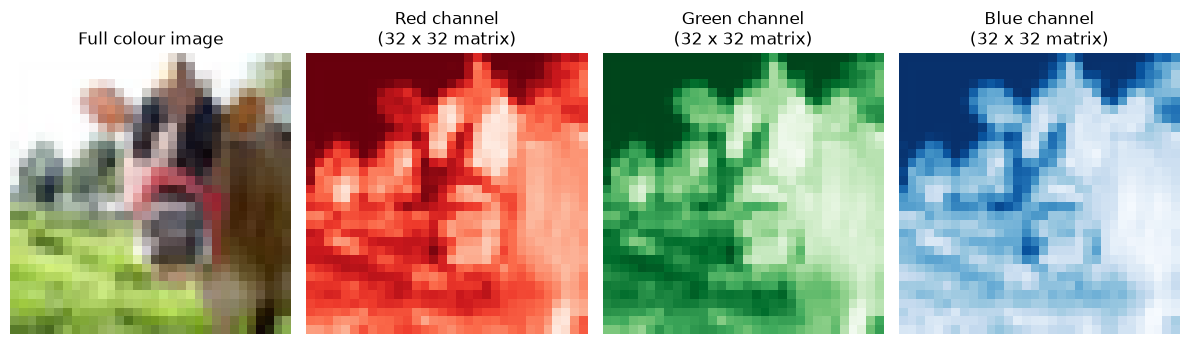

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3.3))
axes[0].imshow(img.astype(np.uint8)); axes[0].set_title("Full colour image")
for ax, ch, name, cmap in zip(axes[1:], (R, G, B), ("Red", "Green", "Blue"), ("Reds", "Greens", "Blues")):
    ax.imshow(ch, cmap=cmap, vmin=0, vmax=255); ax.set_title(f"{name} channel\n(32 x 32 matrix)")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

## 3. How do we apply SVD to a colour image?

SVD factorises a **matrix** (2-D). A colour image is a 3-D array, so there is no "SVD of the image" directly.
Two standard ways around this:

| Method | Idea | Matrix size | Number of SVDs |
|---|---|---|---|
| **A. Per-channel** | Treat R, G, B as three independent grayscale images | 32 × 32 each | 3 |
| **B. Unfold / flatten** | Put the channels side by side: $[\,R \;\|\; G \;\|\; B\,]$ | 32 × 96 | 1 |

(A third option is to convert to grayscale first, but then colour is lost — we want to keep it.)

Both methods are used below. Method A is the most common and easiest to explain; Method B lets one SVD capture
correlations between channels (e.g. a bright pixel tends to be bright in all three channels).

## 4. Method A — SVD of each channel separately

Red  :  U (32, 32)  s (32,)  Vt (32, 32)   largest sigma =   5075.1   smallest = 0.09
Green:  U (32, 32)  s (32,)  Vt (32, 32)   largest sigma =   5103.4   smallest = 0.66
Blue :  U (32, 32)  s (32,)  Vt (32, 32)   largest sigma =   4202.4   smallest = 0.60


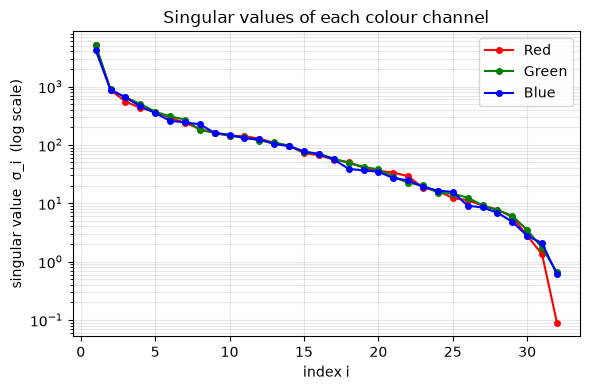

In [ ]:
def svd_per_channel(img):
    """Return a list of (U, s, Vt) — one for each of the 3 colour channels."""
    return [np.linalg.svd(img[:, :, c], full_matrices=False) for c in range(3)]

svds = svd_per_channel(img)
for name, (U, s, Vt) in zip(("Red", "Green", "Blue"), svds):
    print(f"{name:5s}:  U {U.shape}  s {s.shape}  Vt {Vt.shape}   largest sigma = {s[0]:8.1f}   smallest = {s[-1]:.2f}")

plt.figure(figsize=(6, 4))
for (U, s, Vt), name, col in zip(svds, ("Red", "Green", "Blue"), ("r", "g", "b")):
    plt.semilogy(np.arange(1, 33), s, "o-", color=col, label=name, markersize=4)
plt.xlabel("index i"); plt.ylabel("singular value  σ_i  (log scale)")
plt.title("Singular values of each colour channel"); plt.legend(); plt.grid(True, which="both", alpha=0.3)
plt.tight_layout(); plt.show()

k =  5:  relative error = 11.10%   numbers stored =   975  (32% of original)
k = 10:  relative error =  5.51%   numbers stored =  1950  (63% of original)
k = 15:  relative error =  2.51%   numbers stored =  2925  (95% of original)
k = 20:  relative error =  1.04%   numbers stored =  3900  (127% of original)


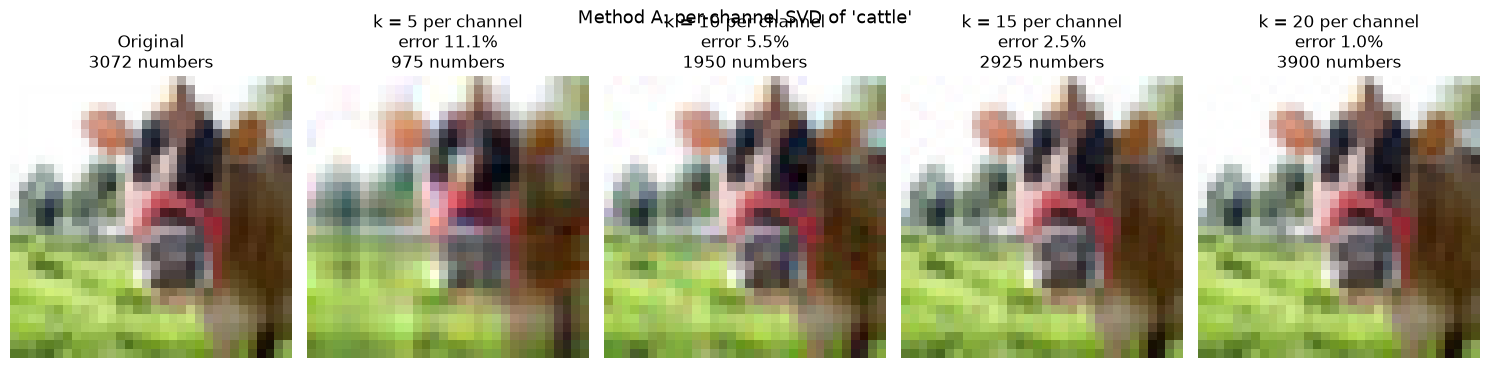

In [ ]:
def reconstruct_per_channel(svds, k):
    """Rank-k approximation of each channel, stacked back into a colour image."""
    channels = [U[:, :k] @ np.diag(s[:k]) @ Vt[:k, :] for (U, s, Vt) in svds]
    return np.stack(channels, axis=2)

def to_uint8(x):
    """Low-rank approximations can slightly overshoot 0..255 — clip before displaying."""
    return np.clip(np.round(x), 0, 255).astype(np.uint8)

ks = [5, 10, 15, 20]
H, W, _ = img.shape

fig, axes = plt.subplots(1, len(ks) + 1, figsize=(3.0 * (len(ks) + 1), 3.8))
axes[0].imshow(to_uint8(img)); axes[0].set_title(f"Original\n{H*W*3} numbers"); axes[0].axis("off")
for ax, k in zip(axes[1:], ks):
    img_k = reconstruct_per_channel(svds, k)
    err = np.linalg.norm(img - img_k) / np.linalg.norm(img)
    stored = 3 * k * (H + W + 1)             # 3 channels x (U_k + s_k + Vt_k)
    ax.imshow(to_uint8(img_k)); ax.set_title(f"k = {k} per channel\nerror {err:.1%}\n{stored} numbers"); ax.axis("off")
    print(f"k = {k:2d}:  relative error = {err:6.2%}   numbers stored = {stored:5d}  ({stored/(H*W*3):.0%} of original)")
fig.suptitle(f"Method A: per-channel SVD of '{CLASS_NAMES[labels[idx]]}'", fontsize=13)
plt.tight_layout(); plt.show()

## 5. Method B — unfold the channels into one 32 × 96 matrix

$M = [\,R \;\|\; G \;\|\; B\,]$ has 32 rows and 96 columns, so it has at most **32** singular values.
One SVD, one truncation, then cut the 96 columns back into three 32-column blocks.

Unfolded matrix shape: (32, 96)
U (32, 32)  s (32,)  Vt (32, 96)
First 10 singular values: [8283.4 1524.3 1171.   950.1  715.1  554.1  481.2  350.4  332.9  287.8]
k =  5:  relative error = 12.57%   numbers stored =   645  (21% of original)
k = 10:  relative error =  6.63%   numbers stored =  1290  (42% of original)
k = 15:  relative error =  3.50%   numbers stored =  1935  (63% of original)
k = 20:  relative error =  1.70%   numbers stored =  2580  (84% of original)


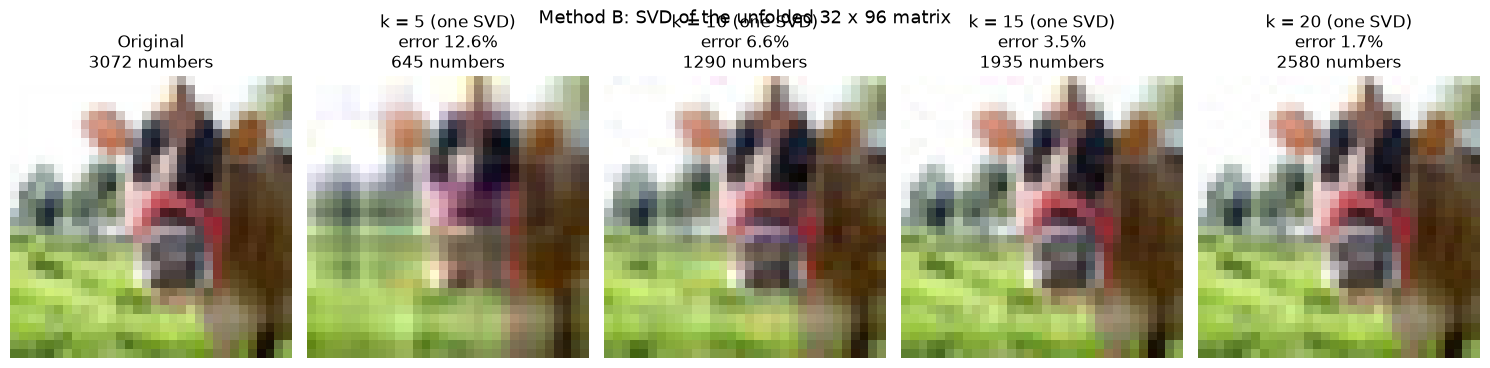

In [ ]:
M = np.hstack([R, G, B])                       # shape (32, 96)
print("Unfolded matrix shape:", M.shape)

U_M, s_M, Vt_M = np.linalg.svd(M, full_matrices=False)
print(f"U {U_M.shape}  s {s_M.shape}  Vt {Vt_M.shape}")
print("First 10 singular values:", np.round(s_M[:10], 1))

def reconstruct_unfolded(U, s, Vt, k, H=32, W=32):
    M_k = U[:, :k] @ np.diag(s[:k]) @ Vt[:k, :]
    return np.stack([M_k[:, 0:W], M_k[:, W:2*W], M_k[:, 2*W:3*W]], axis=2)

fig, axes = plt.subplots(1, len(ks) + 1, figsize=(3.0 * (len(ks) + 1), 3.8))
axes[0].imshow(to_uint8(img)); axes[0].set_title(f"Original\n{H*W*3} numbers"); axes[0].axis("off")
for ax, k in zip(axes[1:], ks):
    img_k = reconstruct_unfolded(U_M, s_M, Vt_M, k)
    err = np.linalg.norm(img - img_k) / np.linalg.norm(img)
    stored = k * (H + 3*W + 1)                  # U_k is 32xk, Vt_k is kx96
    ax.imshow(to_uint8(img_k)); ax.set_title(f"k = {k} (one SVD)\nerror {err:.1%}\n{stored} numbers"); ax.axis("off")
    print(f"k = {k:2d}:  relative error = {err:6.2%}   numbers stored = {stored:5d}  ({stored/(H*W*3):.0%} of original)")
fig.suptitle(f"Method B: SVD of the unfolded 32 x 96 matrix", fontsize=13)
plt.tight_layout(); plt.show()

## 6. Side-by-side pairs, one figure per $k$ (Method A)

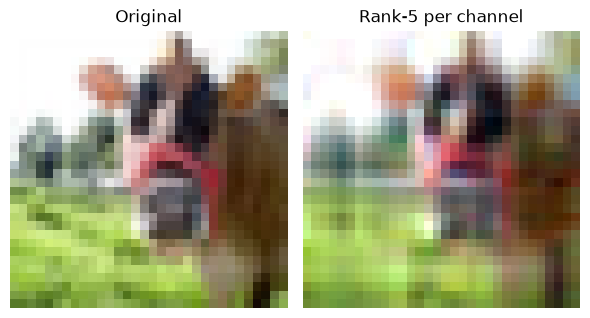

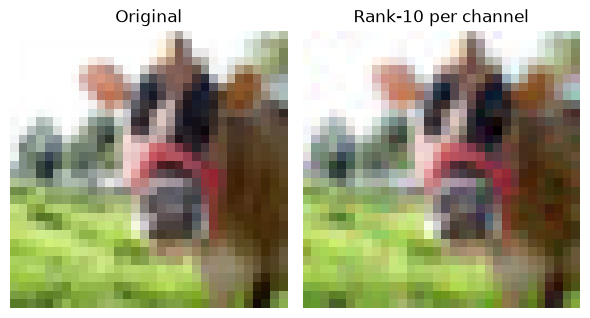

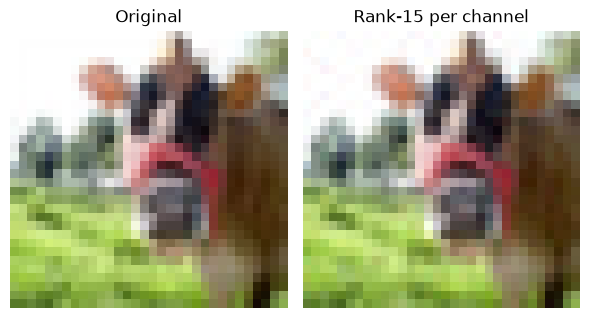

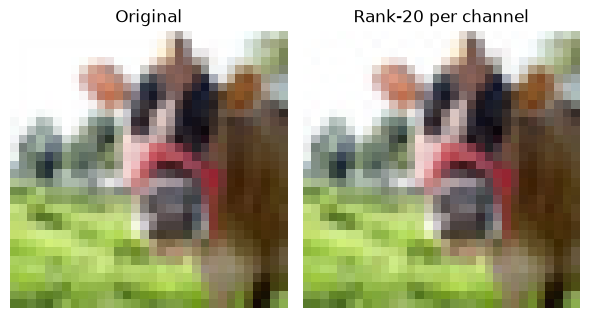

In [ ]:
for k in ks:
    img_k = reconstruct_per_channel(svds, k)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(6, 3.3))
    ax1.imshow(to_uint8(img));   ax1.set_title("Original");                    ax1.axis("off")
    ax2.imshow(to_uint8(img_k)); ax2.set_title(f"Rank-{k} per channel");       ax2.axis("off")
    plt.tight_layout(); plt.show()

## 7. The same for all loaded images
Rows = images, columns = original then $k = 5, 10, 15, 20$ (per-channel SVD).

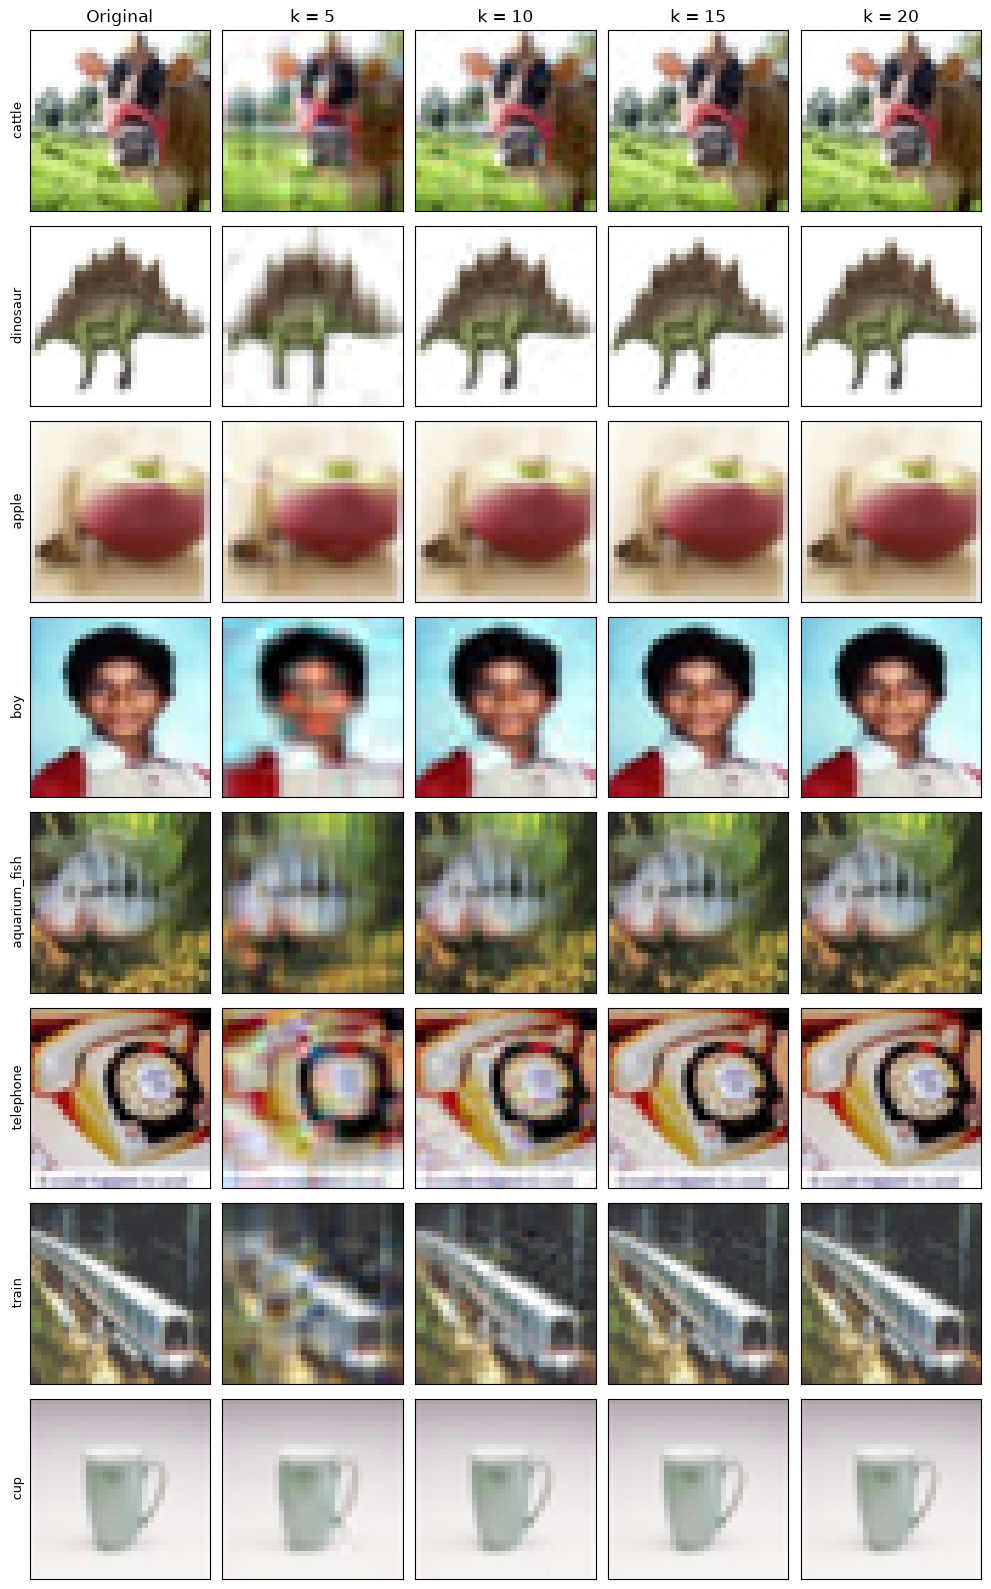

In [ ]:
fig, axes = plt.subplots(N_IMAGES, len(ks) + 1, figsize=(2.0 * (len(ks) + 1), 2.0 * N_IMAGES))
for i in range(N_IMAGES):
    im = images[i].astype(float)
    sv = svd_per_channel(im)
    axes[i, 0].imshow(to_uint8(im)); axes[i, 0].set_ylabel(CLASS_NAMES[labels[i]], fontsize=9)
    for j, k in enumerate(ks):
        axes[i, j + 1].imshow(to_uint8(reconstruct_per_channel(sv, k)))
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([])
axes[0, 0].set_title("Original")
for j, k in enumerate(ks): axes[0, j + 1].set_title(f"k = {k}")
plt.tight_layout(); plt.show()